# 01 — Compute sanity check

**Question:** Which device suits our continuous-control workloads at different network and batch sizes: CPU or Apple MPS?

**Hypothesis before measurement:** Small, sequential policy calls may favor CPU because accelerator dispatch and observation/action transfers add fixed overhead. Larger batches may amortize that overhead. More CPU threads may help larger matrix products but hurt tiny ones. These are expectations, not conclusions.

This is a compute experiment using an **untrained** network. It does not measure learning quality, sample efficiency, or successful control. The saved run below is the evidence; this notebook never launches the benchmark.

## Reproduce through the CLI

From the project root:

```zsh
./doThis.sh test
./doThis.sh compute-sanity --devices cpu mps
./doThis.sh render-notebook --run-dir results/<printed-run-id>
```

The example benchmark command uses the original small-workload defaults. The exact command for the selected run is printed below with its metadata; use that command to reproduce an expanded sweep.\n\nThe renderer supplies the selected run directory and starts a fresh kernel. For later Linux runs use `--devices cpu cuda` inside a GPU allocation, or `--devices cpu` on a CPU-only host. Code: [compute_sanity.py](../../../python/compute_sanity.py), particularly `make_case`, `check_equivalence`, `network_samples`, and `step_environment`. Timing helpers: [timing.py](../../../python/timing.py). Device synchronization and memory definitions: [devices.py](../../../python/devices.py).

In [1]:
from pathlib import Path
RUN_DIR = Path('/Users/choij/workspace/FlyPilot/results/20260917T033507Z_compute_e430bc7a')
FIGURE_DIR = Path('/Users/choij/workspace/FlyPilot/results/20260917T033507Z_compute_e430bc7a/render_20260917T042335Z_e02931/figures')

In [2]:
import json
import sys
from IPython.display import HTML, Image, Markdown, display

ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / 'python' / 'compute_sanity.py').is_file())
sys.path.insert(0, str(ROOT / 'python'))
from plotting import summary_html, interpretation

config = json.loads((RUN_DIR / 'config.json').read_text())
metadata = json.loads((RUN_DIR / 'metadata.json').read_text())
assert json.loads((RUN_DIR / 'status.json').read_text())['status'] == 'complete'
print('Saved run:', RUN_DIR.name)
print(json.dumps(config, indent=2))
print(json.dumps(metadata, indent=2))
print('Exact benchmark command:', metadata['invocation'])
for width in config['widths']:
    print(f'Hidden width {width}: {width**2 + 6*width + 1:,} trainable parameters')

Saved run: 20260917T033507Z_compute_e430bc7a
{
  "devices": [
    "cpu",
    "mps"
  ],
  "widths": [
    512,
    1024
  ],
  "batches": [
    1,
    64,
    256,
    1024,
    4096
  ],
  "seed": 0,
  "warmup": 20,
  "iterations": 100,
  "repetitions": 5,
  "env_steps": 1000,
  "output_root": "/Users/choij/workspace/FlyPilot/results",
  "cpu_thread_counts": [
    1,
    8
  ]
}
{
  "platform": "macOS-27.0-arm64-arm-64bit",
  "machine": "arm64",
  "processor": "Apple M1 Max",
  "physical_memory_bytes": "34359738368",
  "logical_cpus": 10,
  "python": "3.11.13",
  "executable": "/Users/choij/micromamba/envs/flypilot/bin/python",
  "versions": {
    "torch": "2.7.1",
    "numpy": "2.2.6",
    "gymnasium": "1.1.1",
    "matplotlib": "3.10.3"
  },
  "initial_cpu_threads": 8,
  "interop_threads": 10,
  "mps_available": true,
  "cuda_available": false,
  "cuda_version": null,
  "cuda_device": null,
  "mps_fallback": "unset",
  "memory_note": "RSS is process lifetime peak, not per-case peak.

## Workload mathematics and meaning

An observation has three components, matching Pendulum's $(\cos\theta,\sin\theta,\dot\theta)$ representation. For hidden width $h$ selected in the saved configuration, the benchmark network is

$$f_\theta(x)=W_3\tanh\!\left(W_2\tanh(W_1x+b_1)+b_2\right)+b_3.$$

Here $x\in\mathbb R^3$, $W_1\in\mathbb R^{h\times3}$, $W_2\in\mathbb R^{h\times h}$, and $W_3\in\mathbb R^{1\times h}$. The $b_i$ are biases and $\theta$ denotes all trainable parameters. Parameter count is $h^2+6h+1$. The configured widths and their parameter counts are printed above.

For synthetic batch size $B$, use fixed seeded inputs and targets:

$$L(\theta)=\frac1B\sum_{i=1}^B\bigl(f_\theta(x_i)-y_i\bigr)^2,$$
$$\nabla_\theta L=\frac{2}{B}\sum_{i=1}^B\bigl(f_\theta(x_i)-y_i\bigr)\nabla_\theta f_\theta(x_i).$$

$y_i$ is a synthetic scalar target, not a return or Bellman target. Backpropagation traverses the network to accumulate this gradient. No optimizer updates occur, so all repetitions retain the same parameters.

The rollout remains a fixed **width-64** reference, independent of the compute sweep's widths. It uses $a=2\tanh(f_\theta(x))$, respecting Pendulum's torque bounds $[-2,2]$. This probes the observation→policy→action path, not policy competence.

## What exactly do the clocks measure?

For $n$ completed operations over elapsed wall time $\Delta T$,

$$t=\frac{\Delta T}{n},\qquad q_{\rm operations}=\frac{n}{\Delta T},\qquad q_{\rm samples}=\frac{Bn}{\Delta T}.$$

$t$ is seconds per operation, while $q$ is operations/s, samples/s, or environment transitions/s as explicitly labeled. For matched workloads,

$$S=\frac{t_{\rm CPU,\;1\ thread}}{t_{\rm variant}}.$$

$S>1$ means faster than the single-thread CPU reference.

| Measurement | Included | Excluded |
| --- | --- | --- |
| Forward latency | One inference call, completion synchronization | Autograd, input transfer, model construction |
| Backward latency | One prebuilt MSE graph's backward pass, completion synchronization | Forward/loss construction, gradient clearing, transfers |
| Forward + backward block | Gradient clearing, forward, MSE, backward for the full iteration block; synchronization at block boundaries | Optimizer updates, transfers |
| Environment only | Python loop, precomputed action lookup, Gym wrappers and stepping | Initial reset and separately timed episode resets |
| Complete rollout | Observation conversion, inference, action transfer to CPU, Gym stepping and episode resets | Initial reset and model construction |

The backward graph is fresh for every iteration. The clock starts after earlier accelerator work has completed. Per-call latency includes the ending synchronization overhead, while compute-block throughput amortizes it. **Do not add isolated latency measurements to predict block throughput.**

For each repetition, sum its elapsed times and divide by its operation count. Summaries show median and 25th–75th percentiles (IQR) across repetitions. The IQR is descriptive timing variability, not a confidence interval or independent RL-seed evidence. See [PyTorch's benchmarking guidance](https://docs.pytorch.org/tutorials/recipes/recipes/benchmark).

## Controls, correctness, and measurement limitations

Weights and synthetic data are created on CPU with seed 0 and copied to each device. Float32 forward values and parameter gradients must agree within `rtol=1e-4, atol=1e-5` before timing. Every case is warmed up. Device order alternates across repetitions; CPU uses one thread and the host's original thread count in separate variants. This is a fixed sweep, not CPU thread tuning.

The environment baseline uses precomputed random actions; the rollout uses the untrained network, so their trajectories differ. Tiny cross-device numerical differences can also alter later trajectories. No rendering or learning occurs. Loop and wrapper overhead remains in environment timing.

Process peak RSS is a lifetime high-water mark shared across workloads. MPS tensor and Metal-driver allocation counters are snapshots; driver allocations include caches. Neither is a per-workload peak, and CPU/MPS memory is not directly comparable on unified memory. Thermal state, background load, and process order can still affect timing.

In [3]:
checks = json.loads((RUN_DIR / 'correctness.json').read_text())
assert all(c['passed'] for c in checks)
print(f'{len(checks)} matched forward/gradient checks passed.')
print('Largest absolute output difference:', max(c['max_output_abs_error'] for c in checks))
print('Largest absolute gradient difference:', max(c['max_gradient_abs_error'] for c in checks))
resets = json.loads((RUN_DIR / 'environment_details.json').read_text())
print('Environment repetitions:', len(resets))
print('Reset counts:', sorted({r['resets'] for r in resets}))
print('Reset time range (seconds):', min(r['reset_seconds'] for r in resets), max(r['reset_seconds'] for r in resets))
memory = json.loads((RUN_DIR / 'memory.json').read_text())
for key in sorted({k for r in memory for k in r if k.endswith('_bytes')}):
    values = [r[key] for r in memory if key in r]
    print(f'{key}: observed range {min(values)/2**20:.2f}–{max(values)/2**20:.2f} MiB')

20 matched forward/gradient checks passed.
Largest absolute output difference: 2.1606683731079102e-07
Largest absolute gradient difference: 5.960464477539062e-07
Environment repetitions: 20
Reset counts: [5]
Reset time range (seconds): 5.2375e-05 0.000290167
mps_driver_bytes: observed range 1112.69–1114.69 MiB
mps_tensor_bytes: observed range 2.02–17.39 MiB
process_lifetime_peak_rss_bytes: observed range 533.27–699.86 MiB


## Results

Latency and throughput panels include IQR error bars. The speedup chart is a ratio of medians; it is not an uncertainty estimate. Tables below provide the numeric alternative to the figures. Shared plotting and interpretation helpers live in [plotting.py](../../../python/plotting.py).

Figures use PyROOT with cmsstyle and FlyPilot labels. Each render exports PNG images for the notebook, vector PDF figures, and editable ROOT canvases in its own figures directory. The numerical summaries and prior renders are preserved.

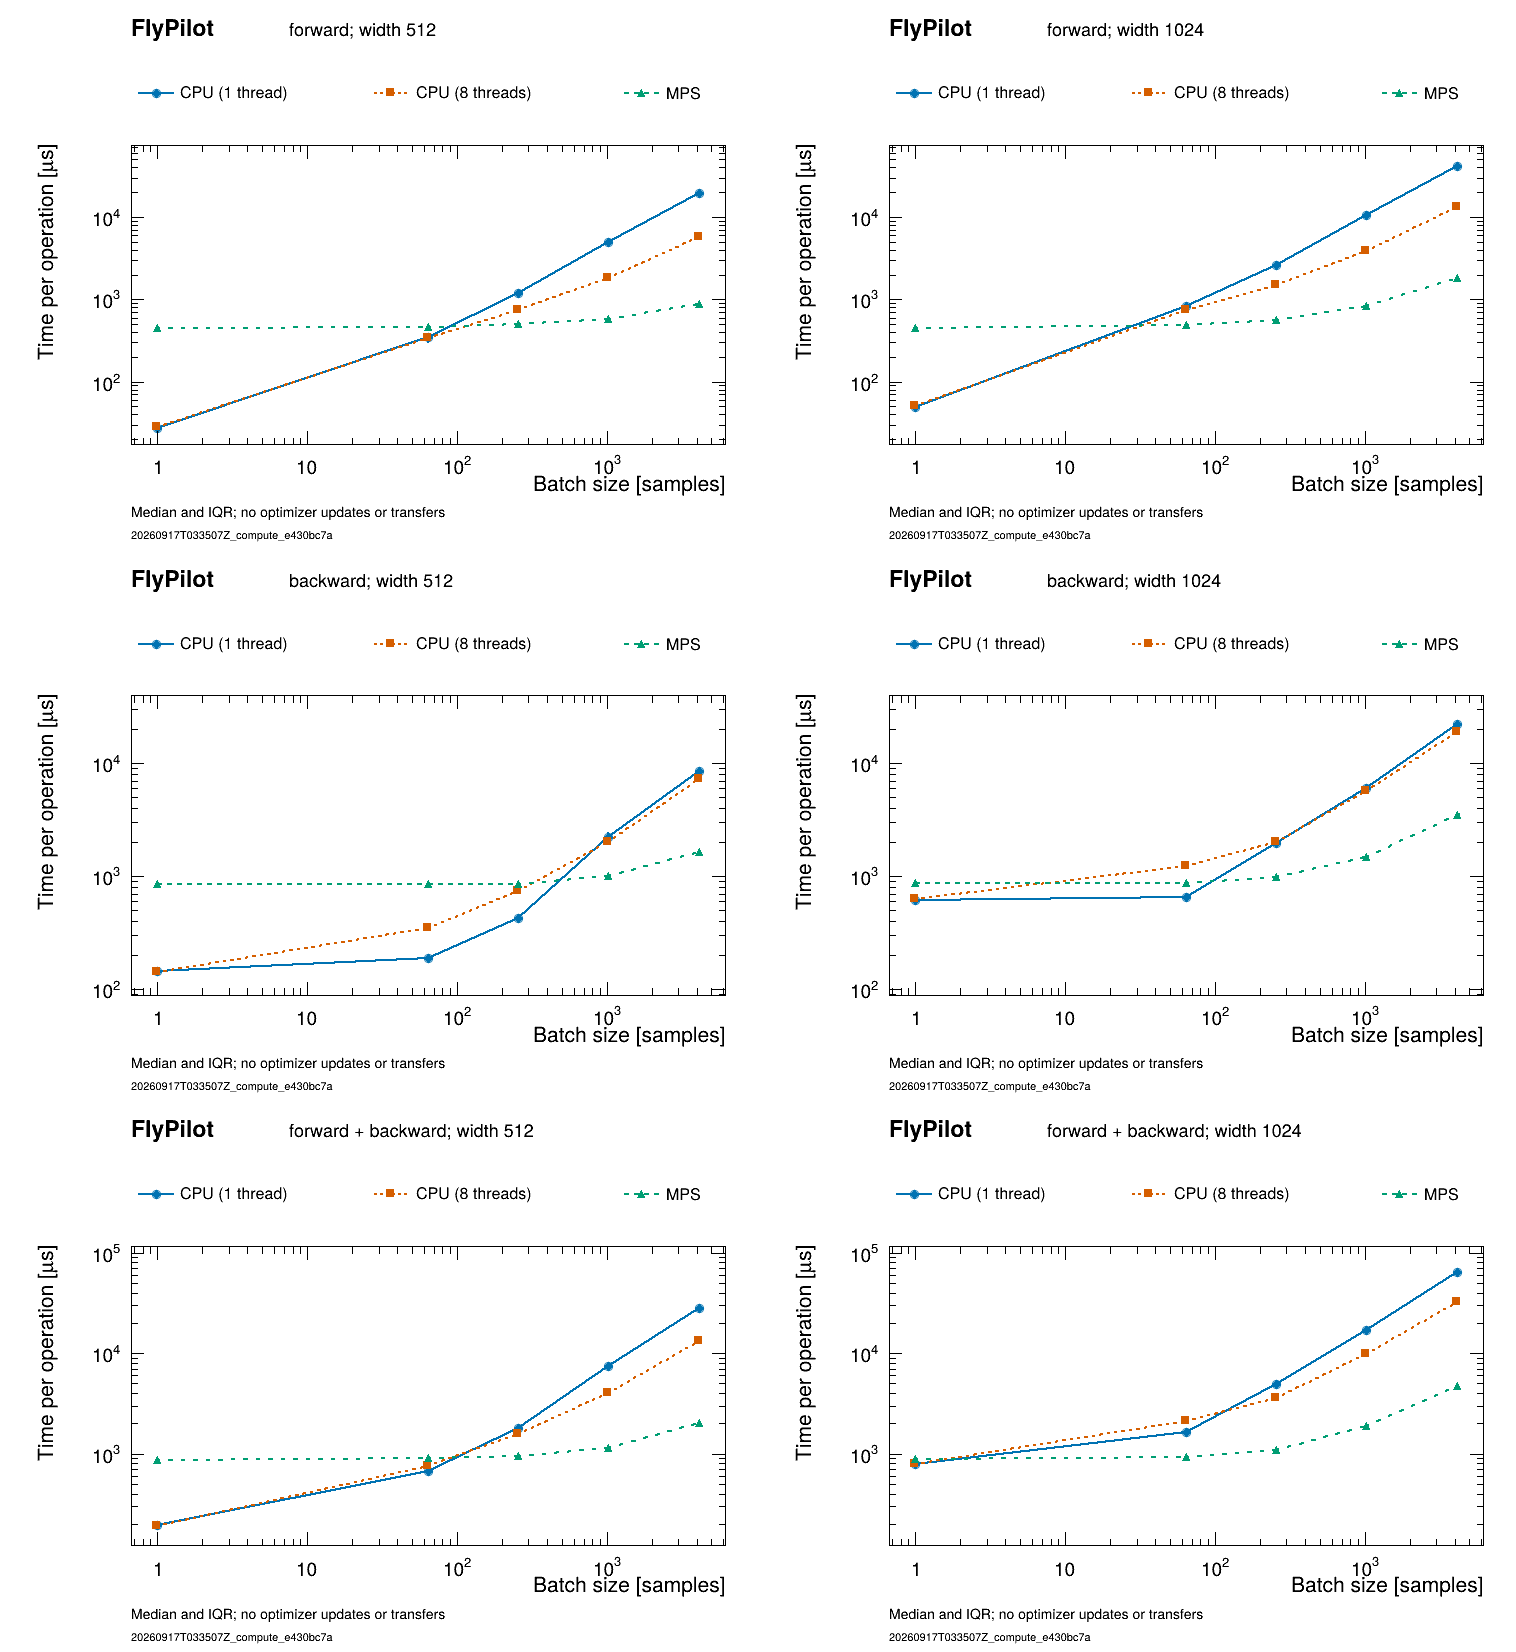

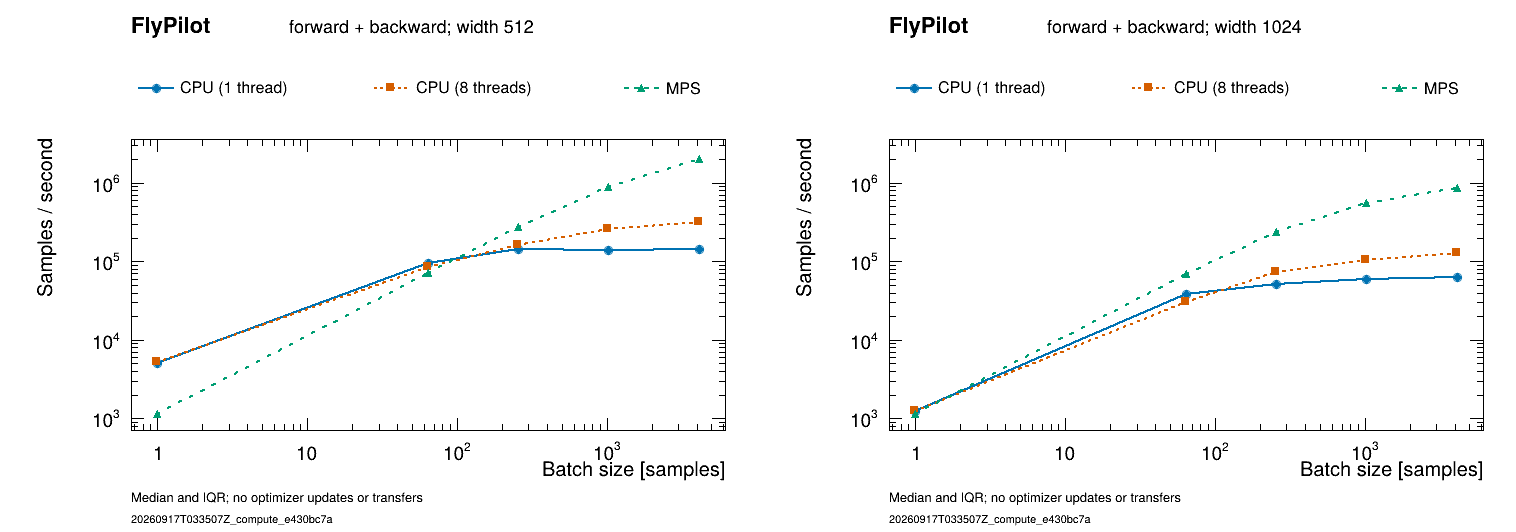

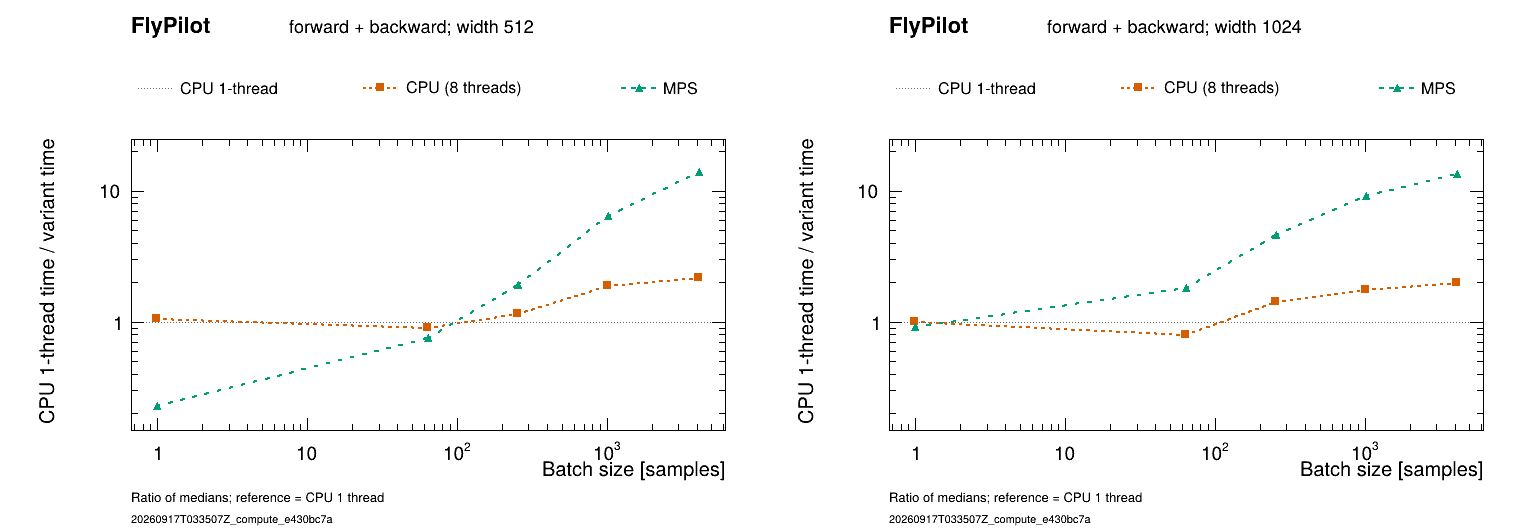

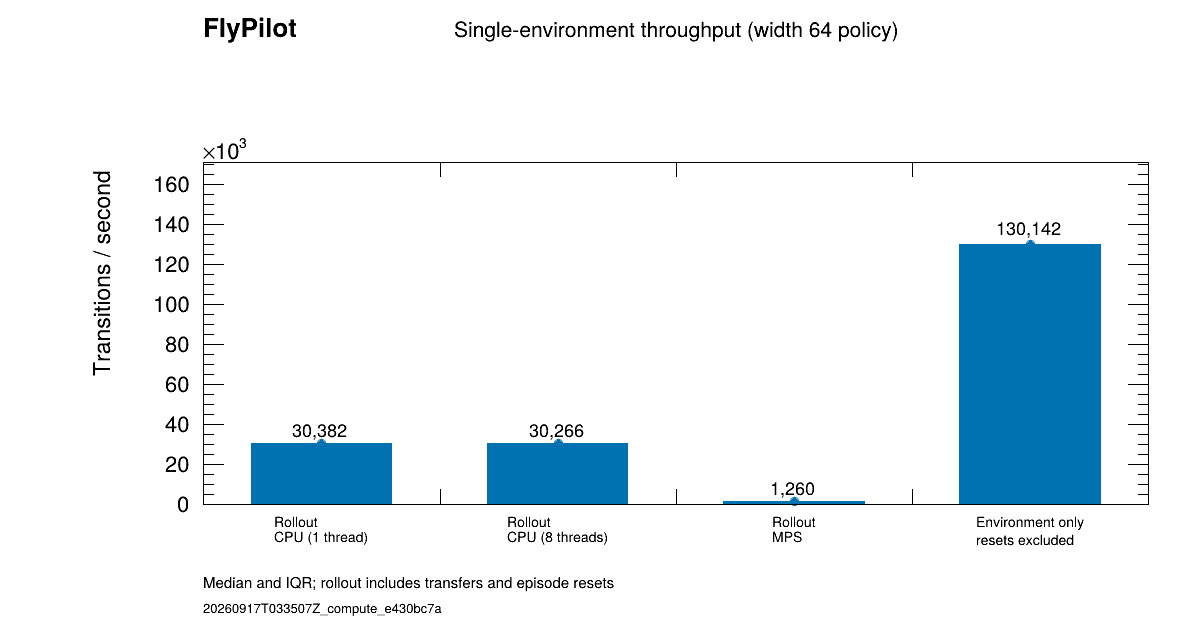

In [4]:
for name in ('latency.png', 'throughput.png', 'speedup.png', 'rollout.png'):
    display(Image(filename=str(FIGURE_DIR / name)))

In [5]:
display(HTML(summary_html(RUN_DIR)))

Metric,Device,Width,Batch,Median µs/op,IQR µs/op,Items/s
forward,CPU (1 thread),512,1,27.19,26.97–28.71,"36,777"
backward,CPU (1 thread),512,1,143.46,137.24–145.95,"6,971"
forward_backward,CPU (1 thread),512,1,197.14,194.24–200.29,"5,073"
forward,CPU (1 thread),512,64,351.22,302.01–365.88,"182,225"
backward,CPU (1 thread),512,64,186.54,186.50–187.12,"343,082"
forward_backward,CPU (1 thread),512,64,676.98,671.83–691.94,"94,537"
forward,CPU (1 thread),512,256,1181.74,1173.33–1187.99,"216,629"
backward,CPU (1 thread),512,256,429.63,422.18–445.67,"595,864"
forward_backward,CPU (1 thread),512,256,1806.28,1788.89–1815.81,"141,727"
forward,CPU (1 thread),512,1024,5007.05,4969.69–5300.89,"204,512"


## Interpretation from this saved run

The following observations are calculated from the saved summaries. Median rankings alone do not establish statistical significance.

In [6]:
display(Markdown(interpretation(RUN_DIR)))

**Observed rollout result:** CPU (1 thread) had the highest median single-environment throughput, 30,382 transitions/s.

**Width 512, batch 4096:** MPS had the highest median compute throughput, 2,005,864 samples/s.

**Width 1024, batch 4096:** MPS had the highest median compute throughput, 861,606 samples/s.

These are rankings of measured medians, not significance tests. Inspect IQRs and raw repetitions before treating small differences as repeatable. Dispatch, synchronization, threading, and transfers are candidate explanations; this experiment does not isolate their individual contributions. Use the rollout result for a provisional single-environment device choice and match the actual training batch before choosing a training device.

## Limits and next question

These results apply to the measured host, software, precision, architecture, and batch sizes. Five repeated timings at one seed do not establish a universal device advantage. The synthetic loss omits an optimizer and RL-specific operations; the rollout is a single environment with a fixed untrained network. CUDA/AlmaLinux/NERSC remain unverified until the same CLI runs there.

**Next question:** When actual rollout collection and training are implemented, does their workload mix favor the same device? Retain these results as a reference and remeasure the actual algorithm before choosing its backend. No later research step is executed as part of this notebook.